# Семинар 1. Генерация текста

Две модели, веса не меняем.

GPT-1 через `transformers` — следующий токен и temperature. Это открытые веса 2018 года, 117M параметров, английский.

Qwen 2.5 3B через Ollama — примеры в промпте на русских отзывах. GPT-1 для этой задачи мала и английская.

Ячейки идут сверху вниз.

## Как модели учились

До 2018 года под каждую задачу в обработке текста собирали свою сеть и десятки тысяч размеченных примеров. Серия GPT показала другой путь. Одна архитектура, и при обучении одна задача: угадать следующий токен. Разметку для этого брать не нужно, следующее слово в тексте уже есть.

GPT-1, 2018 год. Декодер на 117 миллионов параметров, учился на книгах. Сначала предобучение: модель читает кусок и предсказывает продолжение. Потом дообучение на конкретной задаче, но задачу записывают как продолжение текста, а не как отдельную голову под классификацию.

GPT-2 — та же схема, больше текста и параметров, до 1.5 миллиарда. Задачу стало можно написать обычными словами в промпте. Веса при этом не меняют.

GPT-3 — 175 миллиардов. В промпт кладут ноль, один или несколько примеров решения, и модель продолжает в том же виде. Это zero-shot, one-shot и few-shot, вместе их называют in-context learning.

Дальше стало видно, что угадывать следующее слово и отвечать человеку — не одно и то же. Модель дописывает вопрос вместо ответа, уверенно говорит неправду и повторяет вредное из обучающих текстов. Цель предобучения с тем, чего хочет пользователь, не совпадает.

Это чинят выравниванием. Сначала люди сами пишут хорошие ответы, так модель дообучают. Потом на один вопрос собирают несколько ответов и человек выбирает лучший. Из таких пар либо учат отдельного оценщика и подкручивают модель обучением с подкреплением, это RLHF, либо сразу поднимают вероятность хорошего ответа и опускают плохого. Второй способ называется DPO, отдельного оценщика там нет. Маленькая InstructGPT на 1.3 миллиарда людям нравилась чаще, чем GPT-3 на 175.

Сегодня ничего из этого не обучаем. Сначала откроем GPT-1 и посмотрим, как она выбирает следующий токен. Потом на Qwen посмотрим, как примеры в промпте меняют ответ на отзыв.

## Среда на все семинары

Одна и та же `.venv`. В Cursor выберите интерпретатор `.venv/bin/python`.

```bash
python3 -m venv .venv
source .venv/bin/activate
pip install -r requirements.txt
```

Ollama в pip не входит. Её ставят отдельно: [ollama.com](https://ollama.com), на Mac ещё `brew install ollama`.

## Как запускают LLM локально

<img src="img/local_stack.png" width="820">

Веса лежат на Hugging Face. Дальше нужен движок.

- **transformers** — Python и PyTorch. Сегодня так грузим GPT-1: модель маленькая, на CPU хватает, вероятности токенов видны напрямую.
- **llama.cpp** и **MLX** — движки под квантованные веса (GGUF). llama.cpp работает на CPU, MLX — на Mac.
- **Ollama** — команда и локальный сервер поверх этих движков. Сегодня так запускаем Qwen.
- **LM Studio** — те же движки, только кнопками.
- **vLLM** — сервер на GPU, когда запросов много. Не для этого семинара.

В Ollama нет GPT-1. `ollama pull gpt-oss` — другая модель, 20B и 120B.

```bash
ollama serve
ollama pull qwen2.5:3b
```

`qwen2.5:3b` — около 2 ГБ, один раз. Первый запрос читает её в память и поэтому долгий.

## GPT-1

Веса: `openai-community/openai-gpt`, лицензия MIT. Первый запуск скачивает около 500 МБ.

Токенайзер GPT-1 приводит текст к нижнему регистру. Промпты ниже на английском: модель училась на книгах, не на русском.

In [68]:
import math

import torch
from transformers import AutoModelForCausalLM, AutoTokenizer
from transformers.utils import logging

logging.set_verbosity_error()

GPT1 = "openai-community/openai-gpt"
tokenizer = AutoTokenizer.from_pretrained(GPT1)
gpt1 = AutoModelForCausalLM.from_pretrained(GPT1)
gpt1.eval()

Loading weights:   0%|          | 0/146 [00:00<?, ?it/s]

OpenAIGPTLMHeadModel(
  (transformer): OpenAIGPTModel(
    (tokens_embed): Embedding(40478, 768)
    (positions_embed): Embedding(512, 768)
    (drop): Dropout(p=0.1, inplace=False)
    (h): ModuleList(
      (0-11): 12 x Block(
        (attn): Attention(
          (c_attn): Conv1D(nf=2304, nx=768)
          (c_proj): Conv1D(nf=768, nx=768)
          (attn_dropout): Dropout(p=0.1, inplace=False)
          (resid_dropout): Dropout(p=0.1, inplace=False)
        )
        (ln_1): LayerNorm((768,), eps=1e-05, elementwise_affine=True, bias=True)
        (mlp): MLP(
          (c_fc): Conv1D(nf=3072, nx=768)
          (c_proj): Conv1D(nf=768, nx=3072)
          (act): NewGELUActivation()
          (dropout): Dropout(p=0.1, inplace=False)
        )
        (ln_2): LayerNorm((768,), eps=1e-05, elementwise_affine=True, bias=True)
      )
    )
  )
  (lm_head): Linear(in_features=768, out_features=40478, bias=False)
)

In [69]:
n = sum(p.numel() for p in gpt1.parameters())
print(f"{n:_}")

116_534_784


In [70]:
tokenizer

OpenAIGPTTokenizer(name_or_path='openai-community/openai-gpt', vocab_size=40478, model_max_length=512, padding_side='right', truncation_side='right', special_tokens={'unk_token': '<unk>'}, added_tokens_decoder={
	0: AddedToken("<unk>", rstrip=False, lstrip=False, single_word=False, normalized=False, special=True),
})

In [71]:
text = "The unbelievable capitalization."
print(tokenizer.convert_ids_to_tokens(tokenizer(text)["input_ids"]))

['the</w>', 'unbelievable</w>', 'capitali', 'zation</w>', '.</w>']


## Модель продолжает текст

Берём самый вероятный следующий токен, без случайности.

In [72]:
ids = tokenizer("The capital of France is", return_tensors="pt")["input_ids"]
out = gpt1.generate(ids, max_new_tokens=24, do_sample=False)
print(tokenizer.decode(out[0]))

the capital of france is a great city , and the city is a great city . it is a city of great beauty and beauty , and it


In [73]:
ids = tokenizer("The capital of France is", return_tensors="pt")["input_ids"]
for i in range(5):
    out = gpt1.generate(ids, max_new_tokens=24, do_sample=True)
    print(f"Sample {i+1}:", tokenizer.decode(out[0] if out.dim() > 1 else out))

Sample 1: the capital of france is known for its political and social power . " 
 " do n't pretend like you know what i mean . you really do
Sample 2: the capital of france is one of those . 
 it was a hot evening on the first day of spring , and i wore a long red ,
Sample 3: the capital of france is one hundred percent occupied , for the time being . if i am to give you a contract with the head of marseilles ,
Sample 4: the capital of france is more than a city , but it is a city of women who were women of the highest rank before the germans made the
Sample 5: the capital of france is a new world of a different breed . i shall speak only at length with the emperor and he will receive no further discussion


## Следующий токен

<img src="img/token_probability.png" width="720">

Языковая модель не выбирает фразу целиком. На каждом шаге она выдаёт вероятность каждого токена из словаря при условии уже написанного.

$$
P(w_1, w_2, \ldots, w_T) = \prod_{t=1}^{T} P(w_t \mid w_1, \ldots, w_{t-1})
$$

Вероятность фразы — произведение вероятностей выбранных токенов. В коде перемножать дроби опасно: сто чисел вида 0.5 превращаются в ноль. Складывают логарифмы, это то же самое число:

$$
\log P(w_1, \ldots, w_T) = \sum_{t=1}^{T} \log P(w_t \mid w_1, \ldots, w_{t-1})
$$

### Квиз

Промпт «Кот». Модель выбрала «ел» с вероятностью 0.40, затем «рыбу» с 0.50, затем «.» с 0.70.

### Решение

Сложить эти три числа нельзя: выйдет 1.60, а вероятность больше 1 не бывает. Нужно перемножить.

In [74]:
p1, p2, p3 = 0.40, 0.50, 0.70
print("произведение", p1 * p2 * p3)
print("сумма логарифмов", math.log(p1) + math.log(p2) + math.log(p3))
print("сто сомножителей 0.5:", 0.5 ** 100)
print("сто логарифмов:", sum(math.log(0.5) for _ in range(100)))

произведение 0.13999999999999999
сумма логарифмов -1.9661128563728327
сто сомножителей 0.5: 7.888609052210118e-31
сто логарифмов: -69.31471805599453


Дальше то же самое на GPT-1. Три жадных шага после «The capital of France is» и топ-5 на каждом шаге.

Первый токен — не «paris». Модель дописывает книжную фразу, а не отвечает на вопрос. У самого частого варианта вероятность около 0.1, остальное размазано по словарю.


In [75]:
ids = tokenizer("The capital of France is", return_tensors="pt")["input_ids"]
product = 1.0
log_sum = 0.0

for _ in range(3):
    with torch.no_grad():
        logits = gpt1(ids).logits[0, -1]
    probs = torch.softmax(logits, dim=-1)
    top_p, top_i = torch.topk(probs, 5)
    token_id = int(top_i[0])
    probability = float(probs[token_id])
    product *= probability
    log_sum += math.log(probability)
    print("выбран", repr(tokenizer.decode([token_id])), round(probability, 3))
    for p, i in zip(top_p.tolist(), top_i.tolist()):
        print(f"  {tokenizer.decode([i])!r:20} {p:.3f}")
    ids = torch.cat([ids, torch.tensor([[token_id]])], dim=1)

print("фраза:", tokenizer.decode(ids[0]))
print("произведение", round(product, 6))
print("exp(сумма log)", round(math.exp(log_sum), 6))

выбран 'a' 0.099
  'a'                  0.099
  'the'                0.083
  'in'                 0.041
  'not'                0.029
  'located'            0.019
выбран 'great' 0.034
  'great'              0.034
  'very'               0.033
  'small'              0.030
  'place'              0.026
  'city'               0.025
выбран 'city' 0.204
  'city'               0.204
  'place'              0.166
  'deal'               0.027
  'country'            0.018
  'fortress'           0.015
фраза: the capital of france is a great city
произведение 0.00069
exp(сумма log) 0.00069


## Temperature

softmax

$$
P(w_i) = \frac{\exp(z_i)}{\sum_j \exp(z_j)}
$$

До вероятностей модель выдаёт сырые оценки $z_i$. Temperature $T$ делит их перед softmax:

$$
P(w_i) = \frac{\exp(z_i / T)}{\sum_j \exp(z_j / T)}
$$

$T$ близко к нулю — почти всегда берётся самый вероятный токен. $T$ большое — распределение плоское, чаще вылезают редкие токены. Модель от этого не становится умнее.

<img src="img/images.jpeg" width="720">

In [76]:
prompt = "Once upon a time"
ids = tokenizer(prompt, return_tensors="pt")["input_ids"]
for temperature in (0, 0.7, 1.5, 10.0):
    torch.manual_seed(1)
    if temperature == 0:
        out = gpt1.generate(ids, max_new_tokens=30, do_sample=False)
    else:
        out = gpt1.generate(
            ids,
            max_new_tokens=30,
            do_sample=True,
            temperature=temperature,
        )
    print(f"\nT={temperature}")
    print(tokenizer.decode(out[0]))


T=0
once upon a time , i had been a part of the family . i had been the one to help them . i had been the one to help them . 
 i

T=0.7
once upon a time , i was a child in the eyes of the human race . i was raised by my parents in a home that was not a home . my parents

T=1.5
once upon a time he 'd been in touch with his parents , only by accident . his father said that the old man had said that there would be enough old guys after

T=10.0
once upon a time - i wanted in them when anything big started moving - but this thing you see before its mind you had them when there would probably actually exist a small


## Top-p

Top-p не пересчитывает вероятности, как temperature. Он вычёркивает редкие токены из списка, из которого потом идёт обычное семплирование.

Токены сортируют от самого вероятного. Идут сверху вниз и складывают вероятности, пока сумма не станет хотя бы p. Всё, что ниже этой черты, получает вероятность 0. Оставшиеся заново нормируют, чтобы сумма была 1, и из них уже вызывается multinomial.

Допустим, после softmax вероятности такие: 0.20, 0.15, 0.10 и дальше длинный хвост.

При p = 0.3 хватает первых двух: 0.20 + 0.15 = 0.35. Остальные вычеркнуты. Шанс вытянуть редкое слово равен нулю.

При p = 1 нужна вся сумма словаря, она и так равна 1. Никого не вычёркивают, хвост на месте.


In [77]:
prompt = "Once upon a time"
ids = tokenizer(prompt, return_tensors="pt")["input_ids"]
for top_p in (1.0, 0.5, 0.3, 0.1):
    torch.manual_seed(1)
    out = gpt1.generate(
        ids,
        max_new_tokens=30,
        do_sample=True,
        temperature=0.7,
        top_k=0,
        top_p=top_p,
    )
    print(f"\ntop_p={top_p}")
    print(tokenizer.decode(out[0]))



top_p=1.0
once upon a time , i was hard at work , making things happen . but this was different . this was a very special experience . 
 " it 's okay , "

top_p=0.5
once upon a time , i was a child , and i was in love with my father . " 
 " i know , " i said , " but that does n't

top_p=0.3
once upon a time , i had been a good girl . i had been a good girl . i had been a good girl . i had been a good girl . 


top_p=0.1
once upon a time , i had been a part of the family . i had been the one to help them . i had been the one to help them . 
 i


## Что ломается у языковой модели

1. **Не отвечает на вопрос.** На «the capital of france is» самый вероятный токен был `a`, не `paris`. Модель продолжает фразу, а не сообщает столицу.
2. **Вершина распределения низкая.** У этого `a` вероятность около 0.1. Даже лучший вариант модель выбирает неуверенно, остальное размазано по словарю.
3. **Не останавливается.** Ячейка с вопросом «What is the capital of France?» дописывает 40 токенов диалога и сама точку не ставит.
<!-- 4. **Один промпт, разный текст.** В цикле по `seed` промпт один и тот же, `do_sample=True`. Меняется только случайное число в `multinomial`, поэтому четыре продолжения разные. -->

In [78]:
ids = tokenizer("What is the capital of France?", return_tensors="pt")["input_ids"]
out = gpt1.generate(ids, max_new_tokens=40, do_sample=False)
print(tokenizer.decode(out[0]))

what is the capital of france ? " 
 " it is the capital of france , " said the captain . " it is the capital of the french empire . " 
 " and what is the capital of france ? " 
 " the


In [79]:
ids = tokenizer("Once upon a time", return_tensors="pt")["input_ids"]
for seed in (1, 2, 3, 4):
    torch.manual_seed(seed)
    out = gpt1.generate(ids, max_new_tokens=20, do_sample=True, temperature=0.7)
    print(seed, tokenizer.decode(out[0]))

1 once upon a time , i was a child in the eyes of the human race . i was raised by my parents in
2 once upon a time had been a great advantage to the land of the dead . it was a place where the dead could
3 once upon a time , i 've spent the last few years of my life fighting for my life . but now , i
4 once upon a time , the boy had lived in his father 's house . father and son had been inseparable , and father


## In-context learning

Декодер у GPT-1, GPT-2 и GPT-3 один и тот же: следующий токен и только по уже написанному. Выросли параметры, данные и длина контекста.

| | параметры | данные | контекст |
| --- | --- | --- | --- |
| GPT-1 | 117M | книги, около 5 ГБ | 512 |
| GPT-2 | до 1.5B | WebText, 40 ГБ | 1024 |
| GPT-3 | 175B | около 300 млрд токенов | 2048 |

На большом масштабе задачу стало можно задавать текстом, без дообучения.

<img src="img/icl_settings.png" width="900">


<img src="img/icl_scaling.png" width="780">

Чем больше модель, тем сильнее она поднимает точность от примеров в промпте. GPT-1 — это низ графика. Отзывы ниже считаем на Qwen 2.5 3B: та же схема, модель уже умеет русский.


### Тот же приём на GPT-1

Картинка из статьи GPT-3: в промпте описание и примеры, веса не трогаем. На 117M это почти не работает. Ниже ноль примеров и три примера, оба раза про «cheese».

In [80]:
def finish(prompt):
    ids = tokenizer(prompt, return_tensors="pt")["input_ids"]
    out = gpt1.generate(ids, max_new_tokens=6, do_sample=False)
    return tokenizer.decode(out[0])

In [81]:
zero = """
Translate English to German:
cheese =>
"""

In [82]:
print(finish(zero))

translate english to german : cheese = > cheese = > cheese = >


In [83]:
def finish(prompt):
    ids = tokenizer(prompt, return_tensors="pt")["input_ids"]
    out = gpt1.generate(ids, max_new_tokens=6, do_sample=False)
    return tokenizer.decode(out[0])

def finish_w_temperature(prompt, temperature=temperature):
    ids = tokenizer(prompt, return_tensors="pt")["input_ids"]
    out = gpt1.generate(ids, max_new_tokens=6, do_sample=False, temperature=temperature)
    return tokenizer.decode(out[0])

In [84]:
few = """
Translate English to German:
sea => Meer
bread => Brot
water => Wasser
cheese =>
"""

for temperature in (0.0, 0.7, 1, 1.5):
    print(finish_w_temperature(few, temperature))
# print(finish(few))

translate english to german : sea = > meer bread = > brot water = > wasser cheese = > basser cheese = > ba
translate english to german : sea = > meer bread = > brot water = > wasser cheese = > basser cheese = > ba
translate english to german : sea = > meer bread = > brot water = > wasser cheese = > basser cheese = > ba
translate english to german : sea = > meer bread = > brot water = > wasser cheese = > basser cheese = > ba


### Отзывы

Датасет `ai-forever/kinopoisk-sentiment-classification`: отзывы Кинопоиска, три класса в `label_text` — `Good`, `Neutral`, `Bad`. В промпт кладём по одному отзыву каждого класса из train, проверяем по 6 из test. Тексты длинные, в промпт идёт начало. Веса Qwen те же.

Ответ засчитывается, если первое слово — `Good`, `Neutral` или `Bad`. Считаем долю верных, precision и recall по каждому классу.

`raw=True`: в модель уходит ровно этот текст, без спрятанного чат-шаблона. Три прохода по 18 отзывам, первая генерация долгая.


```
curl http://localhost:11434/api/generate \
  -H 'Content-Type: application/json' \
  -d '{"model":"qwen2.5:3b","prompt":"Напиши короткий рассказ о космосе","stream":false}'

In [130]:
from collections import Counter

from datasets import load_dataset
import matplotlib.pyplot as plt
import requests

# MODEL = "qwen2.5:3b"
MODEL = "llama3.1"
OLLAMA = "http://localhost:11434"
LABELS = ("Good", "Neutral", "Bad")

ds = load_dataset("ai-forever/kinopoisk-sentiment-classification")
for split in ds:
    counts = Counter(ds[split]["label_text"])
    print(split, len(ds[split]), {label: counts[label] for label in LABELS})

train 10500 {'Good': 3500, 'Neutral': 3500, 'Bad': 3500}
validation 1500 {'Good': 500, 'Neutral': 500, 'Bad': 500}
test 1500 {'Good': 500, 'Neutral': 500, 'Bad': 500}


In [131]:
def clip(text):
    return " ".join(text.split())[:400]


def take(split, per_label):
    found = {label: [] for label in LABELS}
    for row in ds[split]:
        label = row["label_text"]
        if len(found[label]) < per_label:
            found[label].append((clip(row["text"]), label))
        if all(len(found[label]) == per_label for label in LABELS):
            break
    return found


train_ex = take("train", 5)
test_ex = take("test", 50)

In [132]:
# train_ex

In [133]:
# test_ex

In [134]:
EXAMPLES = [train_ex[label][0] for label in LABELS]
TEST = [pair for label in LABELS for pair in test_ex[label]]

In [135]:
# EXAMPLES

In [136]:
# TEST

In [137]:
def generate(prompt, temperature=0, num_predict=8):
    response = requests.post(
        OLLAMA + "/api/generate",
        json={
            "model": MODEL,
            "prompt": prompt,
            "stream": False,
            "raw": True,
            "keep_alive": "30m",
            "options": {
                "temperature": temperature,
                "num_predict": num_predict,
                "seed": 1,
            },
        },
        timeout=180,
    )
    response.raise_for_status()
    return response.json()

In [138]:
def build_prompt(review, examples):
    lines = ["Определи тональность отзыва. Ответь одним словом: Good, Neutral или Bad."]
    for text, label in examples:
        lines.append("Отзыв: " + text)
        lines.append("Ответ: " + label)
    lines.append("Отзыв: " + review)
    lines.append("Ответ:")
    return "\n".join(lines)

In [139]:
def first_label(text):
    word = text.strip().split()[0].lower().strip(".,!:;")
    for label in LABELS:
        if word == label.lower():
            return label
    return "?"


def precision_recall(pairs, label):
    tp = sum(gold == label and pred == label for gold, pred in pairs)
    fp = sum(gold != label and pred == label for gold, pred in pairs)
    fn = sum(gold == label and pred != label for gold, pred in pairs)
    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / (tp + fn) if tp + fn else 0.0
    return precision, recall


def show_scores(pairs):
    accuracy = sum(gold == pred for gold, pred in pairs) / len(pairs)
    print(f"  accuracy {accuracy:.0%}")
    for label in LABELS:
        precision, recall = precision_recall(pairs, label)
        print(f"  {label:8}  precision {precision:.0%}  recall {recall:.0%}")
    return accuracy


In [140]:
tags = requests.get(OLLAMA + "/api/tags", timeout=5)
tags.raise_for_status()
names = [model["name"] for model in tags.json()["models"]]
print(names)
if not any(name.startswith(MODEL) for name in names):
    print("скачиваю", MODEL)
    pulled = requests.post(
        OLLAMA + "/api/pull",
        json={"model": MODEL, "stream": False},
        timeout=1800,
    )
    pulled.raise_for_status()
    print(pulled.json()["status"])

print("примеров", len(EXAMPLES), "проверка", len(TEST))

MODES = [
    ("zero-shot", []),
    ("one-shot", EXAMPLES[:1]),
    ("few-shot", EXAMPLES),
]

['llama3.1:latest', 'qwen2.5:3b']
примеров 3 проверка 150



zero-shot
  ok  ждали Good      получили Good      Начинала смотреть два раза, и только на второй д
  ok  ждали Good      получили Good      Может, вы мне и не поверите, но фильм я полность
  нет  ждали Good      получили Bad       Ненависть порождает месть, а месть, как известно
  ok  ждали Good      получили Good      На самом деле меня фильм порадовал и на мой взгл
  ok  ждали Good      получили Good      Сиквел Шерлока Холмса получился очень ярким. В н
  ok  ждали Good      получили Good      - Разве это похоже на танец? - Конечно! А что я,
  нет  ждали Good      получили Bad       Тема смертной казни практически неисчерпаема. Бу
  нет  ждали Good      получили Neutral   К сожалению, я из тех кто не смог почувствовать 
  ok  ждали Good      получили Good      Фильм скачал давно, но времени все не хватало, ч
  ok  ждали Good      получили Good      Самое ценное в кино — это его суть, идея и смысл
  ok  ждали Good      получили Good      Несмотря на то что я люблю историю про Шерлок

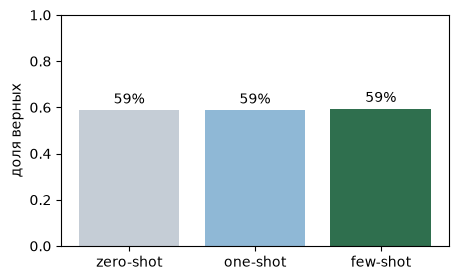

In [141]:
scores = []
for mode, examples in MODES:
    pairs = []
    print("\n" + mode)
    for review, gold in TEST:
        data = generate(build_prompt(review, examples))
        pred = first_label(data["response"])
        pairs.append((gold, pred))
        mark = "ok" if pred == gold else "нет"
        print(f"  {mark}  ждали {gold:8}  получили {pred:8}  {review[:48]}")
    scores.append(show_scores(pairs))

fig, ax = plt.subplots(figsize=(5, 3))
ax.bar(["zero-shot", "one-shot", "few-shot"], scores, color=["#c5cdd6", "#8fb8d6", "#2f6f4e"])
ax.set_ylim(0, 1)
ax.set_ylabel("доля верных")
for i, accuracy in enumerate(scores):
    ax.text(i, accuracy + 0.03, f"{accuracy:.0%}", ha="center")
plt.show()



zero-shot
  нет  ждали Good      получили Bad       Начинала смотреть два раза, и только на второй д
  ok  ждали Good      получили Good      Может, вы мне и не поверите, но фильм я полность
  нет  ждали Good      получили Bad       Ненависть порождает месть, а месть, как известно
  ok  ждали Good      получили Good      На самом деле меня фильм порадовал и на мой взгл
  ok  ждали Good      получили Good      Сиквел Шерлока Холмса получился очень ярким. В н
  ok  ждали Good      получили Good      - Разве это похоже на танец? - Конечно! А что я,
  нет  ждали Good      получили Bad       Тема смертной казни практически неисчерпаема. Бу
  нет  ждали Good      получили Bad       К сожалению, я из тех кто не смог почувствовать 
  ok  ждали Good      получили Good      Фильм скачал давно, но времени все не хватало, ч
  ok  ждали Good      получили Good      Самое ценное в кино — это его суть, идея и смысл
  ok  ждали Good      получили Good      Несмотря на то что я люблю историю про Шерло

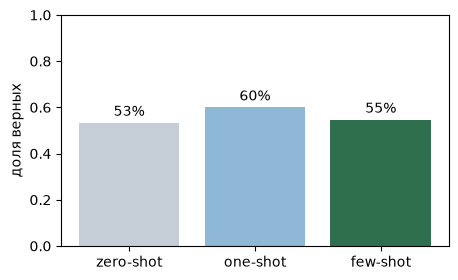

In [129]:
scores = []
for mode, examples in MODES:
    pairs = []
    print("\n" + mode)
    for review, gold in TEST:
        data = generate(build_prompt(review, examples))
        pred = first_label(data["response"])
        pairs.append((gold, pred))
        mark = "ok" if pred == gold else "нет"
        print(f"  {mark}  ждали {gold:8}  получили {pred:8}  {review[:48]}")
    scores.append(show_scores(pairs))

fig, ax = plt.subplots(figsize=(5, 3))
ax.bar(["zero-shot", "one-shot", "few-shot"], scores, color=["#c5cdd6", "#8fb8d6", "#2f6f4e"])
ax.set_ylim(0, 1)
ax.set_ylabel("доля верных")
for i, accuracy in enumerate(scores):
    ax.text(i, accuracy + 0.03, f"{accuracy:.0%}", ha="center")
plt.show()
